# Problem 3.3

Consider the following mathematical model:

$$\frac{u_1^2}{4} + u_2^2 = 1$$

$$4 u_1 u_2 = \pi$$

$$f = 4(u_1 + u_2).$$

Solve this model by hand. Write these equations in residual form and use a numerical solver to obtain the same solution.

In [192]:
%reset -f
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

Hand calculations:

subsitute: $u_2 = \frac{\pi}{4 \cdot u_1}$  
add into first equation: $\frac{u_1^2}{4} + (\frac{\pi}{4 \cdot u_1})^2 = 1$  
simplify and reorder: $u_1^4 - 4 \cdot u_1^2 + \frac{\pi^2}{4} = 0$  
with: $\frac{\pi^2}{4} \approx 2.467401$  
substitute $u_1^2 = x$  
this gives: $x^2 - 4x + 2.467401 = 0$  
solve for x: $x_1 \approx 0.76201, x_2 \approx 3.23798$  
this results in four solutions for u1: $u_1^{(1)} = 0.872932, u_1^{(2)} = - 0.872932, u_1^{(3)} = 1.79944, u_1^{(4)} = - 1.79944$  
plugging these into the second equation and solving for u2 gives: $u_2^{(1)} = 0.899720, u_2^{(2)} = - 0.899720, u_2^{(3)} = 0.436468, u_2^{(4)} = - 0.436468$  
with f: $f^{(1)} = 7.090625, f^{(2)} = - 7.090625, f^{(3)} = 8.943630, f^{(4)} = - 8.943630$ 

In [193]:
# machine solver

def residuals(u):
    u1, u2 = u
    return np.array([
        0.25 * u1**2 + u2**2 - 1,
        4 * u1 * u2 - np.pi,
    ])

def jacobian(u):
    u1, u2 = u
    return np.array([
        [0.5 * u1, 2 * u2],
        [4 * u2,   4 * u1],
    ])

def func(u):
    u1, u2 = u
    return 4*(u1 + u2)

def print_u(u):
    u1, u2 = u
    print(f"u1: {u1:.6f}, u2: {u2:.6f}, f(u): {func(u):.6f}")

def solve_system(u0, max_iter=10, tol=1e-7):
    u = u0
    converged = False
    for i in range(max_iter):
        r = residuals(u)
        J = jacobian(u)
        du = np.linalg.solve(J, -r)
        if np.linalg.norm(du) < tol:  # convergence criterion
            converged = True
            break
        u = u + du
    print_u(u)
    print(f"{'converged' if converged else 'NOT converged'} after {i} iterations. Residual norm: {np.linalg.norm(residuals(u)):.6e}")
    return u


print(1)
u1 = solve_system(np.array([2.0, 0.5]))
print(2)
u2 = solve_system(np.array([1.0, 1.0]))
print(3)
u3 = solve_system(np.array([-1.0, -1.0]))
print(4)
u4 = solve_system(np.array([-2.0, -0.5]))



1
u1: 1.799439, u2: 0.436468, f(u): 8.943630
converged after 3 iterations. Residual norm: 1.816375e-09
2
u1: 0.872937, u2: 0.899720, f(u): 7.090625
converged after 3 iterations. Residual norm: 1.816375e-09
3
u1: -0.872937, u2: -0.899720, f(u): -7.090625
converged after 3 iterations. Residual norm: 1.816375e-09
4
u1: -1.799439, u2: -0.436468, f(u): -8.943630
converged after 3 iterations. Residual norm: 1.816375e-09


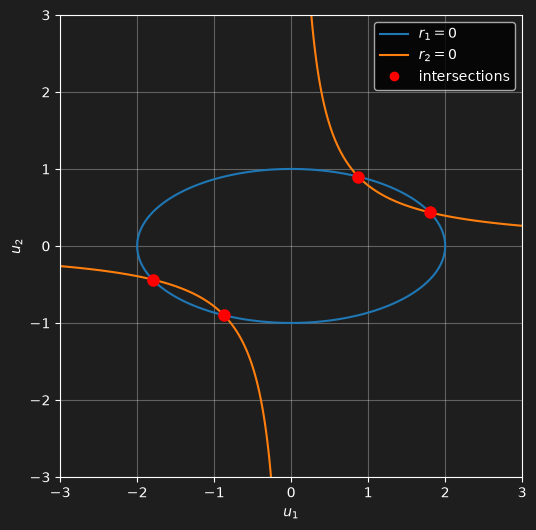

In [194]:
u1_grid, u2_grid = np.meshgrid(np.linspace(-3, 3, 600), np.linspace(-3, 3, 600))
R = residuals([u1_grid, u2_grid])   # plot the residual lines

fig, ax = plt.subplots(figsize=(6, 6))
c1 = ax.contour(u1_grid, u2_grid, R[0], levels=[0], colors="tab:blue")
c2 = ax.contour(u1_grid, u2_grid, R[1], levels=[0], colors="tab:orange")

# plot the intersection points that were previusly calculated
ax.plot(u1[0], u1[1], "ro", ms=8)
ax.plot(u2[0], u2[1], "ro", ms=8)
ax.plot(u3[0], u3[1], "ro", ms=8)
ax.plot(u4[0], u4[1], "ro", ms=8)

ax.set_xlabel("$u_1$")
ax.set_ylabel("$u_2$")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(
    handles=[
        plt.Line2D([], [], color="tab:blue", label="$r_1 = 0$"),
        plt.Line2D([], [], color="tab:orange", label="$r_2 = 0$"),
        plt.Line2D([], [], marker="o", color="r", ls="", label="intersections"),
    ]
)
fig.patch.set_facecolor("#1e1e1e")
ax.set_facecolor("#1e1e1e")
plt.show()


In [195]:
# double check solution with scipy's fsolve

u0 = np.array([1.0, 2.0])

u_newton = solve_system(u0)
u_scipy, info, ier, msg = optimize.fsolve(residuals, u0, fprime=jacobian, full_output=True)

print("scipy:   ", u_scipy, "|", msg)
print("max diff:", np.max(np.abs(u_newton - u_scipy)))
print("residual:", residuals(u_scipy))

u1: 0.872937, u2: 0.899720, f(u): 7.090625
converged after 5 iterations. Residual norm: 2.367063e-09
scipy:    [0.87294 0.89972] | The solution converged.
max diff: 1.2392745718514675e-09
residual: [-0. -0.]


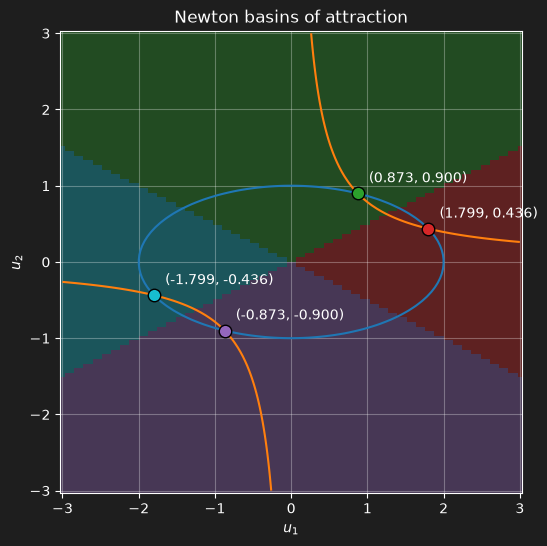

In [196]:
#which starting point converges to which solution?

def newton_quiet(u0, max_iter=50, tol=1e-7):
    u = np.array(u0, dtype=float)
    for _ in range(max_iter):
        try:
            du = np.linalg.solve(jacobian(u), -residuals(u))
        except np.linalg.LinAlgError:   # singular Jacobian (u1 = ±2 u2)
            return u, False
        if np.linalg.norm(du) < tol:
            return u, True
        u = u + du
    return u, False

# the four solutions as before
roots = np.array([u1, u2, u3, u4])

# classify each grid point by the root it converges to (-1 = no convergence)
n = 100
g1, g2 = np.meshgrid(np.linspace(-3, 3, n), np.linspace(-3, 3, n))
basin = np.full(g1.shape, -1)
for idx in np.ndindex(g1.shape):
    u_end, ok = newton_quiet((g1[idx], g2[idx]))
    if ok:
        basin[idx] = np.argmin(np.linalg.norm(roots - u_end, axis=1))

# plot
from matplotlib.colors import ListedColormap
colors = ["tab:red", "tab:green", "tab:purple", "tab:cyan"][: len(roots)]
cmap = ListedColormap(["gray"] + colors)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pcolormesh(g1, g2, basin, cmap=cmap, vmin=-1, vmax=len(roots) - 1, alpha=0.35, shading="auto")

# same residual curves as the earlier plot
R = residuals([g1, g2])
ax.contour(g1, g2, R[0], levels=[0], colors="tab:blue")
ax.contour(g1, g2, R[1], levels=[0], colors="tab:orange")

for k, ru in enumerate(roots):
    ax.plot(*ru, "o", color=colors[k], mec="k", ms=9)
    ax.annotate(f"({ru[0]:.3f}, {ru[1]:.3f})", ru, textcoords="offset points", xytext=(8, 8))

ax.set_xlabel("$u_1$")
ax.set_ylabel("$u_2$")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.set_title("Newton basins of attraction")
fig.patch.set_facecolor("#1e1e1e")
ax.set_facecolor("#1e1e1e")
plt.show()


## Results

the results show that the system converges quickly to a solution (usually less than 10 iterations). there are to be several solutions as seen by the examples given. this makes sense since r1 is an ellipse and r2 is a hyperbola crossing the ellipse there are 4 total points where these functions cross. so there are four solutions in total. the comparison with scipy.optimize shows that both solvers converge to the same solution given the same starting point.

## Interpretation

a nonlinear system can have multiple solutions. so when solving a system this has to be taken into account that depending on the starting point one might get different results. solving a system can be very computationaly intensive when done "incorrectly" like inverting the jacobian in the newton iteration. so instead of inverting the jacobian it is more efficient to use a linear solver to get to a solution. this saves time.